# 11 - Killing rate (γ) vs. antibiotic degradation by living R (φ_max): is the relation linear?

**Question.** Is there a linear relation between γ and φ_max in the two-strain model?

**Definitions**

- **γ (y-axis):** maximum lysis coefficient, how hard the antibiotic kills.
- **φ_max (x-axis):** maximum rate at which living resistant cells degrade the antibiotic. With the
  inhibitor present the effective rate is φ = φ_max(1 − c·ι) = 0.31 × φ_max at the base dose i = 10.

**How "linear" is tested.** φ_max does not enter the equation for the R/S ratio; it only shortens the
time the antibiotic stays. So the test is empirical. For each γ, root-finding gives the φ_max that holds
an endpoint at a fixed level (an **iso-line**: more killing offset by more degradation). The relation is
linear if φ_max on that line is a straight-line function of γ. Both the fit (R²) and the change of
slope along the line are reported.

**Variation levels**

| Axis | Range | Values | Note |
|---|---|---|---|
| γ | 1.1 - 3.1 | 21 + base (1.38) | paper's range 1.1 - 1.4, extended (group choice) as in notebook 10 |
| φ_max | 0 - 5 | 21 (base 1 on the grid) | paper's range |
| a0 | 2.15 and 10 | 2 | base dose and a strongly killing dose |

22 × 21 × 2 = 924 runs with the same engine and endpoints as every other notebook (plain model).
Iso-lines are followed up to φ_max = 40, beyond the paper's range, so their shape can be seen.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from src.analysis import kill_degradation as kd
from src.analysis.kill_degradation import GAMMA_AXIS, PHI_AXIS, DOSES, LOSS_LEVELS, PHI_SEARCH_MAX, linear_fit
from src.analysis.plotting import OKABE_ITO
from src.model.ma2024_model import DEFAULT_PARAMS

FORCE_RERUN = False
path = TABLES / "grid_gamma_phimax.csv"
if path.exists() and not FORCE_RERUN:
    df = pd.read_csv(path)
else:
    df = kd.run_plane(); df.to_csv(path, index=False, float_format="%.8g")
BASE_GAMMA, BASE_PHI = DEFAULT_PARAMS.gamma, DEFAULT_PARAMS.phi_max
base = {a0: df[(df.a0 == a0) & np.isclose(df.gamma, BASE_GAMMA) & np.isclose(df.phi_max, BASE_PHI)].iloc[0][["peak_loss_S", "f_R_final"]].to_dict() for a0 in DOSES}
path = TABLES / "iso_lines_gamma_phimax.csv"
if path.exists() and not FORCE_RERUN:
    iso = pd.read_csv(path)
else:
    iso = kd.run_iso_lines(base); iso.to_csv(path, index=False, float_format="%.8g")
iso = iso[~((iso.endpoint == "peak_loss_S") & (iso.level > 0.99995))]      # at a0 = 10 the base loss is ~100%: not a usable level
print(f"{len(df):,} runs; all settled: {bool(df.ss_converged.all())}; outcomes: {df.outcome.value_counts().to_dict()}")
print("Base point (γ = 1.38, φ_max = 1):", {a0: {k: round(v, 3) for k, v in b.items()} for a0, b in base.items()})
df.groupby("a0")[["peak_loss_S", "log_kill_S", "f_R_final", "t_regain_S"]].agg(["min", "max"]).round(3)

924 runs; all settled: True; outcomes: {'S viable, R persists': 924}
Base point (γ = 1.38, φ_max = 1): {2.15: {'peak_loss_S': 0.394, 'f_R_final': 0.433}, 10.0: {'peak_loss_S': 1.0, 'f_R_final': 0.109}}


peak_loss_S      log_kill_S          f_R_final        t_regain_S       
              min  max        min      max       min    max        min    max
a0                                                                           
2.15        0.000  1.0      0.000   35.135     0.137  0.462        0.0  108.5
10.00       0.258  1.0      0.299  160.905     0.004  0.439        7.5  341.0

## The γ × φ_max plane

White lines: iso-lines of peak S loss (50%, 90%, 99%, 99.99%) found by root-finding. Red cross: base point (top row only).
Top row: base dose. Bottom row: a0 = 10.

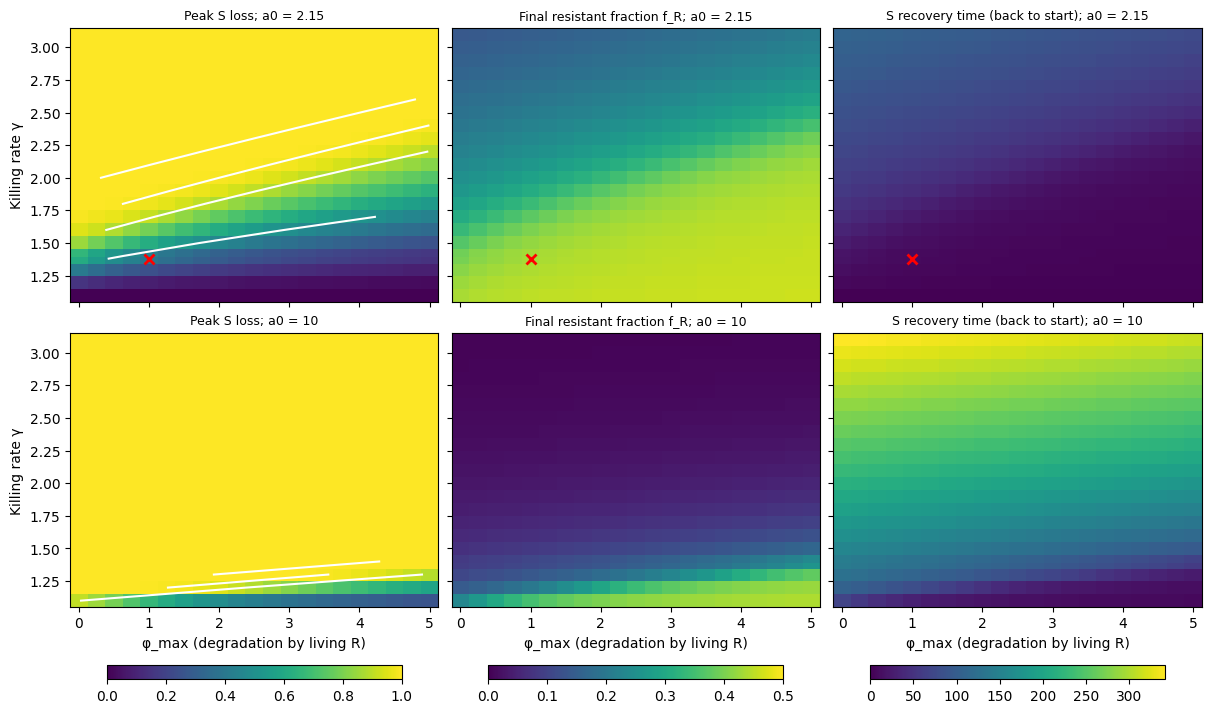

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True, sharex=True, sharey=True)
panels = [("peak_loss_S", "Peak S loss", 0, 1), ("f_R_final", "Final resistant fraction f_R", 0, 0.5), ("t_regain_S", "S recovery time (back to start)", 0, None)]
for r, a0 in enumerate(DOSES):
    sub = df[df.a0 == a0]
    for c_, (col, lab, lo, hi) in enumerate(panels):
        ax = axes[r, c_]
        piv = sub.pivot(index="gamma", columns="phi_max", values=col)
        im = ax.pcolormesh(piv.columns, piv.index, piv.values, cmap="viridis", vmin=lo, vmax=hi if hi else df[col].max(), shading="nearest")
        if c_ == 0:
            for lv in LOSS_LEVELS:
                g = iso[(iso.a0 == a0) & (iso.endpoint == "peak_loss_S") & np.isclose(iso.level, lv) & (iso.phi_iso <= 5)].sort_values("gamma")
                ax.plot(g.phi_iso, g.gamma, color="white", lw=1.5)
        if a0 == 2.15:                                        # the base point is at the base dose only
            ax.plot(BASE_PHI, BASE_GAMMA, marker="x", color="red", ms=7, mew=2)
        ax.set_title(f"{lab}; a0 = {a0:g}", fontsize=9); ax.set_xlim(-0.125, 5.125)
        if r == 1: ax.set_xlabel("φ_max (degradation by living R)")
        if c_ == 0: ax.set_ylabel("Killing rate γ")
        if r == 1: fig.colorbar(im, ax=axes[:, c_], shrink=0.8, location="bottom", pad=0.02)
plt.show()

## Iso-lines: the φ_max that offsets a given γ

Each line holds one endpoint fixed. Solid: peak S loss levels. Dashed: final resistant fraction at its
base-point value. Thin grey lines: straight-line fits. Shaded band: the paper's φ_max range (0-5).

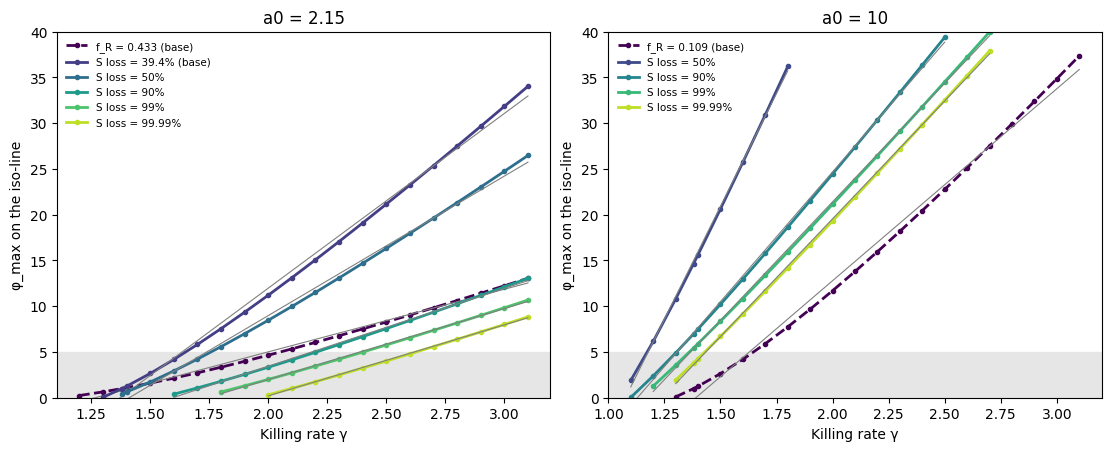

R² from 0.9936 to 0.9997; largest deviation from 1.1% to 5.5% of the range
Slope at the high-γ end is 1.15 to 2.20 times the slope at the low-γ end
γ band inside the paper's φ_max range: {2.15: (0.35, 0.91), 10.0: (0.07, 0.35)}


points  γ from  γ to  slope (φ_max per unit γ)      R²  largest deviation  slope at low-γ end  slope at high-γ end  \
dose a0 line                                                                                                                                        
2.15    f_R = 0.433 (base)         21    1.20   3.1                    6.8413  0.9939             0.0549              3.9947               8.1923   
        S loss = 39.4% (base)      20    1.30   3.1                   19.0853  0.9961             0.0423             11.8516              21.9534   
        S loss = 50%               19    1.38   3.1                   15.2368  0.9968             0.0344             10.1145              17.3094   
        S loss = 90%               16    1.60   3.1                    8.5030  0.9983             0.0278              6.8276               9.4049   
        S loss = 99%               14    1.80   3.1                    7.7522  0.9991             0.0192              6.7413               8.3831   
        S loss = 99.99%            12    2.00   3.1                    7.7600  0.9995             0.0137              7.0579               8.2507   
10.00   f_R = 0.109 (base)         20    1.30   3.1                   20.9741  0.9936             0.0532             11.3686              24.9797   
        S loss = 50%                9    1.10   1.8                   49.3334  0.9989             0.0207             42.5932              52.6290   
        S loss = 90%               16    1.10   2.5                   28.3549  0.9991             0.0221             23.5407              30.2166   
        S loss = 99%               17    1.20   2.7                   25.9161  0.9995             0.0153             22.8541              27.3056   
        S loss = 99.99%            16    1.30   2.7                   25.7374  0.9997             0.0108             23.4981              26.9393   

                               slope ratio (high/low)  bends upward everywhere  γ band inside φ_max 0-5  
dose a0 line                                                                                             
2.15    f_R = 0.433 (base)                     2.0508                     True                   0.9118  
        S loss = 39.4% (base)                  1.8524                     True                   0.3541  
        S loss = 50%                           1.7113                     True                   0.4194  
        S loss = 90%                           1.3775                     True                   0.6614  
        S loss = 99%                           1.2435                     True                   0.6956  
        S loss = 99.99%                        1.1690                     True                   0.6714  
10.00   f_R = 0.109 (base)                     2.1973                     True                   0.3549  
        S loss = 50%                           1.2356                     True                   0.0729  
        S loss = 90%                           1.2836                     True                   0.2042  
        S loss = 99%                           1.1948                     True                   0.2168  
        S loss = 99.99%                        1.1464                     True                   0.2118

In [3]:
def line_label(e, lv, a0):
    if e == "f_R_final": return f"f_R = {lv:.3f} (base)"
    return f"S loss = {lv * 100:g}%" if lv in LOSS_LEVELS else f"S loss = {lv * 100:.1f}% (base)"

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
rows = []
for ax, a0 in zip(axes, DOSES):
    groups = [(k, g.dropna().sort_values("gamma")) for k, g in iso[iso.a0 == a0].groupby(["endpoint", "level"])]
    groups = [(k, g) for k, g in groups if len(g) >= 3]
    for ((e, lv), g), col in zip(groups, plt.cm.viridis(np.linspace(0, 0.9, len(groups)))):
        f = linear_fit(g.gamma, g.phi_iso)
        ax.plot(g.gamma, g.phi_iso, color=col, lw=2, marker="o", ms=3, ls="--" if e == "f_R_final" else "-", label=line_label(e, lv, a0))
        ax.plot(g.gamma, f["slope"] * g.gamma + f["intercept"], color="0.5", lw=0.8)
        local = np.diff(g.phi_iso.values) / np.diff(g.gamma.values)          # slope of each segment of the line
        gamma_at_0 = g.gamma.iloc[0] - g.phi_iso.iloc[0] / local[0]            # where the line meets φ_max = 0 (first segment extended)
        gamma_at_5 = float(np.interp(5.0, g.phi_iso.values, g.gamma.values)) if g.phi_iso.max() >= 5 else np.nan
        rows.append({"dose a0": a0, "line": line_label(e, lv, a0), "points": f["n"], "γ from": g.gamma.min(), "γ to": g.gamma.max(),
                     "slope (φ_max per unit γ)": f["slope"], "R²": f["r2"], "largest deviation": f["max_dev"],
                     "slope at low-γ end": local[0], "slope at high-γ end": local[-1], "slope ratio (high/low)": local[-1] / local[0],
                     "bends upward everywhere": bool(np.all(np.diff(local) > -1e-6 * abs(local).max())),
                     "γ band inside φ_max 0-5": gamma_at_5 - max(gamma_at_0, GAMMA_AXIS.min())})
    ax.axhspan(0, 5, color="0.9", zorder=0)
    ax.set(xlabel="Killing rate γ", ylabel="φ_max on the iso-line", title=f"a0 = {a0:g}", ylim=(0, PHI_SEARCH_MAX))
    ax.legend(frameon=False, fontsize=7.5)
plt.show()
fits = pd.DataFrame(rows).set_index(["dose a0", "line"])
print(f"R² from {fits['R²'].min():.4f} to {fits['R²'].max():.4f}; largest deviation from {fits['largest deviation'].min():.1%} to {fits['largest deviation'].max():.1%} of the range")
print(f"Slope at the high-γ end is {fits['slope ratio (high/low)'].min():.2f} to {fits['slope ratio (high/low)'].max():.2f} times the slope at the low-γ end")
print("γ band inside the paper's φ_max range:", {a0: (round(float(fits.loc[a0, 'γ band inside φ_max 0-5'].min()), 2), round(float(fits.loc[a0, 'γ band inside φ_max 0-5'].max()), 2)) for a0 in DOSES})
fits.round(4)

## At a fixed γ: how the endpoints change with φ_max

Top: base dose. Bottom: a0 = 10. One line per γ.

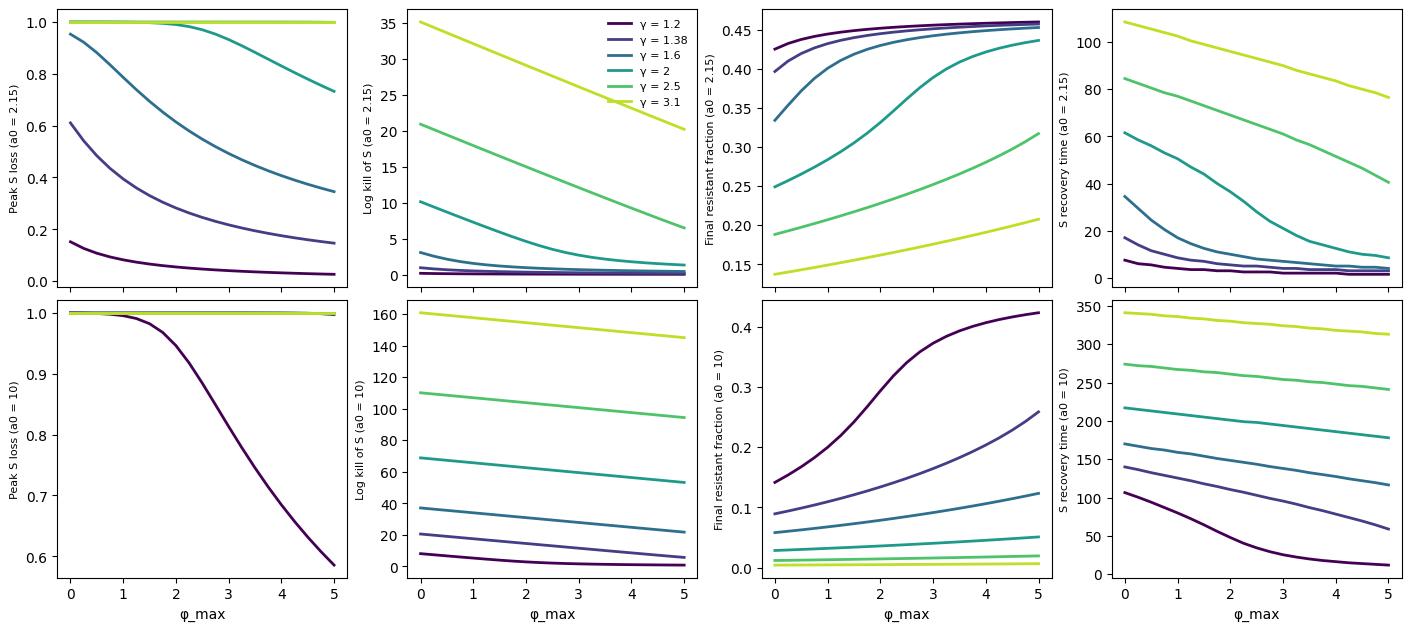

R² of straight-line fits at fixed γ:


log kill of S at φ_max = 0  R²: log kill of S vs φ_max  R²: log kill of S vs 1/(1 + φ_max)  R²: final f_R vs φ_max  R²: S recovery time vs φ_max
dose a0 γ                                                                                                                                                     
2.15    1.20                       0.165                       0.809                               0.999                   0.826                         0.815
        1.38                       0.943                       0.816                               0.998                   0.795                         0.782
        1.60                       3.057                       0.797                               0.998                   0.794                         0.787
        2.00                      10.122                       0.932                               0.917                   0.978                         0.974
        2.50                      20.912                       1.000                               0.796                   0.987                         0.995
        3.10                      35.135                       1.000                               0.791                   0.997                         1.000
10.00   1.20                       8.141                       0.882                               0.951                   0.951                         0.929
        1.38                      20.602                       1.000                               0.791                   0.972                         0.997
        1.60                      37.127                       1.000                               0.788                   0.990                         1.000
        2.00                      68.883                       1.000                               0.788                   0.994                         1.000
        2.50                     110.156                       1.000                               0.788                   0.996                         0.999
        3.10                     160.905                       1.000                               0.788                   0.996                         0.999

Change in peak S loss that γ (1.1-3.1) makes at one φ_max (smallest, largest): {2.15: (1.0, 1.0), 10.0: (0.09, 0.74)} | smallest peak S loss on the grid: {2.15: 0.0, 10.0: 0.26}
Largest change in peak S loss that φ_max (0-5) can make at one γ: {2.15: (0.61, 1.6), 10.0: (0.65, 1.1)} (change, at γ)


In [4]:
gammas = [1.2, 1.38, 1.6, 2.0, 2.5, 3.1]
shades = plt.cm.viridis(np.linspace(0.0, 0.9, len(gammas)))
cols = [("peak_loss_S", "Peak S loss"), ("log_kill_S", "Log kill of S"), ("f_R_final", "Final resistant fraction"), ("t_regain_S", "S recovery time")]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.2), constrained_layout=True, sharex=True)
for r, a0 in enumerate(DOSES):
    for g, col in zip(gammas, shades):
        s = df[(df.a0 == a0) & np.isclose(df.gamma, g)].sort_values("phi_max")
        for ax, (y, lab) in zip(axes[r], cols):
            ax.plot(s.phi_max, s[y], color=col, lw=2, label=f"γ = {g:g}")
    for ax, (y, lab) in zip(axes[r], cols):
        ax.set_ylabel(f"{lab} (a0 = {a0:g})", fontsize=8)
        if r == 1: ax.set_xlabel("φ_max")
axes[0, 1].legend(frameon=False, fontsize=8)
plt.show()
rows = []
for a0 in DOSES:
    for g in gammas:
        s = df[(df.a0 == a0) & np.isclose(df.gamma, g)]
        rows.append({"dose a0": a0, "γ": g, "log kill of S at φ_max = 0": s.log_kill_S.max(),
                     "R²: log kill of S vs φ_max": linear_fit(s.phi_max, s.log_kill_S)["r2"],
                     "R²: log kill of S vs 1/(1 + φ_max)": linear_fit(1 / (1 + s.phi_max), s.log_kill_S)["r2"],
                     "R²: final f_R vs φ_max": linear_fit(s.phi_max, s.f_R_final)["r2"],
                     "R²: S recovery time vs φ_max": linear_fit(s.phi_max, s.t_regain_S)["r2"]})
print("R² of straight-line fits at fixed γ:")
display(pd.DataFrame(rows).set_index(["dose a0", "γ"]).round(3))
gspan = df.groupby(["a0", "phi_max"]).peak_loss_S.agg(lambda v: v.max() - v.min())
print("Change in peak S loss that γ (1.1-3.1) makes at one φ_max (smallest, largest):", {a0: (round(float(gspan[a0].min()), 2), round(float(gspan[a0].max()), 2)) for a0 in DOSES},
      "| smallest peak S loss on the grid:", {a0: round(float(df[df.a0 == a0].peak_loss_S.min()), 2) for a0 in DOSES})
span = df.groupby(["a0", "gamma"]).peak_loss_S.agg(lambda v: v.max() - v.min())
print("Largest change in peak S loss that φ_max (0-5) can make at one γ:", {a0: (round(float(span[a0].max()), 2), float(span[a0].idxmax())) for a0 in DOSES}, "(change, at γ)")

## Takeaways

- **Close to linear, with a slope that rises along each line.** The φ_max needed to hold an endpoint
  fixed rises with γ on every one of the eleven lines. A straight line stays within 1–6% of the range
  (R² = 0.994–0.9997), but every line bends upward: the local slope at the high-γ end is 1.2 to 2.2
  times the slope at the low-γ end. Only the high-loss lines (99% and above) are close to straight.
- **The exchange rate is steep.** At the base dose, each +0.1 in γ needs on average +0.8 (99% loss line)
  to +1.9 (39% loss line) more φ_max to keep peak S loss unchanged. At a0 = 10 it needs +2.6 to +4.9.
- **So degradation can offset only a narrow band of killing rates.** The paper's φ_max range is 0–5. Inside
  it a line of equal outcome covers a γ band of only 0.35–0.91 at the base dose and 0.07–0.35 at a0 = 10;
  the lines had to be followed to φ_max = 40 to see their shape.
- **Composition follows the same pattern.** The φ_max that keeps the final resistant fraction at its base
  value is also a near-straight, upward-bending line in γ (R² = 0.994).
- **At a fixed γ, the effect of φ_max depends on how strong the killing is.** With strong killing the log
  kill of S falls linearly with φ_max (R² = 1.000). With weak killing it follows 1/(1 + φ_max) more closely
  (R² = 0.998), so the first unit of φ_max matters most.
- **γ has the longer reach at the base dose.** There γ takes peak S loss from 0% to 100% at every φ_max,
  while φ_max (0–5) moves it by at most 61 points (at γ = 1.6). At a0 = 10 the loss never drops below 26%,
  and γ (9–74 points) and φ_max (up to 65 points) have comparable reach.

**Limits.** γ is extended beyond the paper's 1.1–1.4 and the lines beyond the paper's φ_max range (group
choices, needed to see the shape). With the inhibitor at i = 10 the effective degradation is 0.31 × φ_max.
Plain model, no extinction floor. All other parameters at base. The near-linearity is an empirical result
of this model over these ranges; no formula was derived for it.